# Deer driver v1: baseline YOLO evaluation

This notebook evaluates the cached 26-class North American wildlife YOLO model against the derived `deer-driver-v1` bounding-box dataset. The untouched test split is the primary result.

Two model views are reported:

- **Strict mule deer:** only the model's `mule_deer` class counts as deer.
- **Driver hazard union:** `mule_deer`, `elk`, and `moose` are collapsed into one warning class. This measures whether a class-confused ungulate detection could still support a driver warning.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'scripts').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from scripts.evaluate_deer_driver_dataset import (  # noqa: E402
    EvaluatedImage,
    box_iou,
    evaluate_dataset,
    load_cache,
)

DATASET = PROJECT_ROOT / 'data/derived/deer-driver-v1'
REPORT_PATH = (
    PROJECT_ROOT / 'notebooks/results/deer_driver_v1_baseline_report.json'
)
CACHE_PATH = (
    PROJECT_ROOT / 'notebooks/results/deer_driver_v1_baseline_predictions.jsonl'
)

assert DATASET.exists(), 'Run scripts.derive_deer_driver_dataset first'
print('Dataset:', DATASET.resolve())


/home/vivek/Documents/Vivek-projects/WildGuard/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: /home/vivek/Documents/Vivek-projects/WildGuard/data/derived/deer-driver-v1


## Run inference and compute metrics

Predictions are retained down to confidence 0.001 so AP and threshold curves can be calculated. The cache makes later notebook runs analysis-only; delete it or set `reuse_cache=False` to rerun the model.


In [2]:
report = evaluate_dataset(
    dataset=DATASET,
    report_path=REPORT_PATH,
    cache_path=CACHE_PATH,
    batch_size=32,
    confidence_floor=0.001,
    reuse_cache=CACHE_PATH.exists(),
)
print(f"Evaluated {report['runtime']['images']:,} images")
print(f"Mean processing time: {report['runtime']['mean_processing_ms']:.2f} ms/image")
print(f"Saved report: {REPORT_PATH}")
print(f"Saved prediction cache: {CACHE_PATH}")


Evaluated 1,448 images
Mean processing time: 12.03 ms/image
Saved report: /home/vivek/Documents/Vivek-projects/WildGuard/notebooks/results/deer_driver_v1_baseline_report.json
Saved prediction cache: /home/vivek/Documents/Vivek-projects/WildGuard/notebooks/results/deer_driver_v1_baseline_predictions.jsonl


## Primary test-set results


In [3]:
for view_name, view in report['views'].items():
    test = view['by_split']['test']
    at_025 = test['thresholds']['0.25']
    best = test['best_f1_at_iou50']
    print(f"\n{view_name} ({', '.join(view['class_names'])})")
    print(f"  AP50: {test['ap50']:.3f}")
    print(f"  mAP50-95: {test['map50_95']:.3f}")
    print(
        f"  @ conf 0.25 — precision {at_025['precision']:.3f}, "
        f"recall {at_025['recall']:.3f}, F1 {at_025['f1']:.3f}"
    )
    print(
        "  Positive-image localization recall: "
        f"{at_025['positive_image_localization_recall']:.3f}"
    )
    print(
        "  Negative-image false-positive rate: "
        f"{at_025['false_positive_image_rate']:.3f}"
    )
    print(
        f"  Best test F1 {best['f1']:.3f} "
        f"at confidence {best['confidence']:.3f}"
    )



strict_mule_deer (mule_deer)
  AP50: 0.358
  mAP50-95: 0.155
  @ conf 0.25 — precision 0.660, recall 0.297, F1 0.410
  Positive-image localization recall: 0.326
  Negative-image false-positive rate: 0.047
  Best test F1 0.467 at confidence 0.024

driver_hazard_union (mule_deer, elk, moose)
  AP50: 0.619
  mAP50-95: 0.346
  @ conf 0.25 — precision 0.673, recall 0.595, F1 0.632
  Positive-image localization recall: 0.698
  Negative-image false-positive rate: 0.103
  Best test F1 0.695 at confidence 0.413


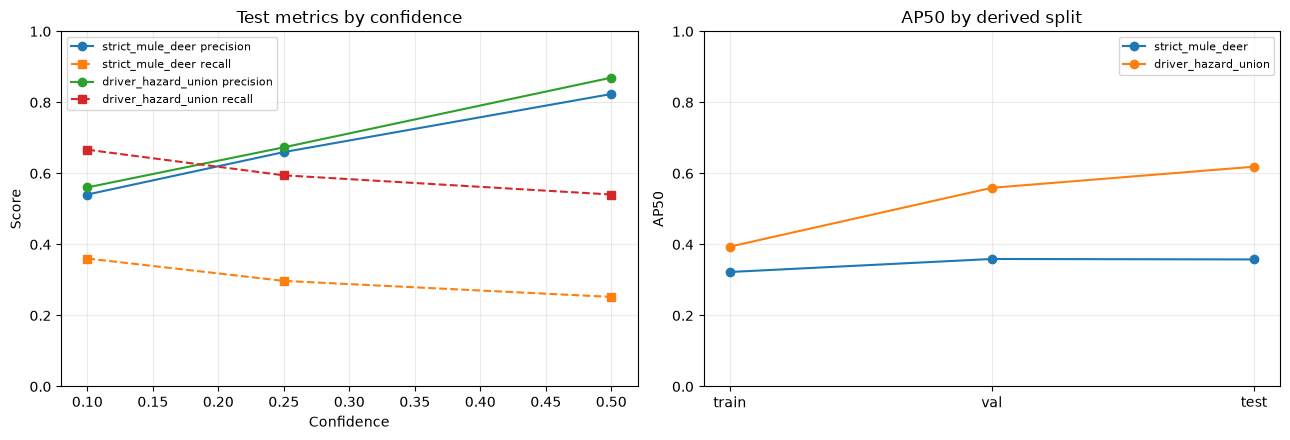

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for view_name, view in report['views'].items():
    thresholds = view['by_split']['test']['thresholds']
    xs = [float(value) for value in thresholds]
    precision = [thresholds[value]['precision'] for value in thresholds]
    recall = [thresholds[value]['recall'] for value in thresholds]
    axes[0].plot(xs, precision, marker='o', label=f'{view_name} precision')
    axes[0].plot(
        xs, recall, marker='s', linestyle='--', label=f'{view_name} recall'
    )
    splits = ['train', 'val', 'test']
    axes[1].plot(
        splits,
        [view['by_split'][split]['ap50'] for split in splits],
        marker='o',
        label=view_name,
    )
axes[0].set(
    title='Test metrics by confidence',
    xlabel='Confidence',
    ylabel='Score',
    ylim=(0, 1),
)
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)
axes[1].set(title='AP50 by derived split', ylabel='AP50', ylim=(0, 1))
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


## Source and object-size analysis


In [5]:
for view_name, view in report['views'].items():
    print(f'\n{view_name}')
    for source, metrics in view['test_by_source'].items():
        at_025 = metrics['thresholds']['0.25']
        print(
            f"  {source}: AP50={metrics['ap50']:.3f}, "
            f"precision={at_025['precision']:.3f}, "
            f"recall={at_025['recall']:.3f}"
        )
    sizes = (
        view['by_split']['test']['thresholds']['0.25']
        ['recall_by_relative_box_size']
    )
    print('  Test recall by relative box size @ conf 0.25:')
    for size, values in sizes.items():
        print(
            f"    {size}: {values['recall']:.3f} "
            f"({values['matched_boxes']}/{values['ground_truth_boxes']})"
        )



strict_mule_deer
  alberta-wildlife-v1: AP50=0.472, precision=0.600, recall=0.429
  ena24: AP50=0.261, precision=0.900, recall=0.164
  Test recall by relative box size @ conf 0.25:
    small: 0.333 (8/24)
    medium: 0.367 (18/49)
    large: 0.184 (7/38)

driver_hazard_union
  alberta-wildlife-v1: AP50=0.452, precision=0.481, recall=0.446
  ena24: AP50=0.773, precision=0.891, recall=0.745
  Test recall by relative box size @ conf 0.25:
    small: 0.417 (10/24)
    medium: 0.531 (26/49)
    large: 0.789 (30/38)


## Model class confusion on deer boxes

The following counts include any model class whose prediction overlaps a test deer box at IoU 0.50 and confidence 0.10. They show whether missed strict detections are being localized under the wrong wildlife label.


{
  "mule_deer": 40,
  "elk": 22,
  "moose": 16,
  "coyote": 15,
  "mountain_lion": 5,
  "badger": 2,
  "gray_wolf": 2,
  "bobcat": 2,
  "swift_fox": 2,
  "jackrabbit": 1,
  "pronghorn": 1,
  "grizzly_bear": 1
}


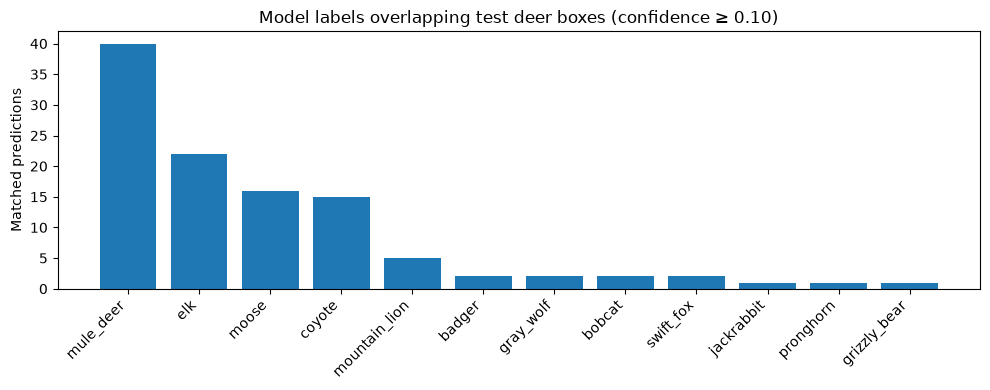

In [6]:
confusion = report['test_ground_truth_overlap_classification_at_confidence_0.10']
print(json.dumps(confusion, indent=2))
if confusion:
    labels = list(confusion)
    values = [confusion[label] for label in labels]
    plt.figure(figsize=(10, 4))
    plt.bar(labels, values)
    plt.title('Model labels overlapping test deer boxes (confidence ≥ 0.10)')
    plt.ylabel('Matched predictions')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


## Prediction galleries

Green boxes are derived ground truth. Predicted boxes are labeled with the model class and confidence: cyan for `mule_deer`, orange for `elk`, magenta for `moose`, and red for other wildlife classes. The galleries use the test split at confidence 0.25 and IoU 0.50.


In [7]:
cached_images, _ = load_cache(CACHE_PATH)
test_images = [item for item in cached_images if item.split == 'test']
STRICT_IDS = frozenset({4})
CONFUSED_UNGULATE_IDS = frozenset({5, 9})
HAZARD_IDS = STRICT_IDS | CONFUSED_UNGULATE_IDS
DISPLAY_CONFIDENCE = 0.25
DISPLAY_IOU = 0.50


def localized_predictions(
    item: EvaluatedImage, class_ids: frozenset[int]
) -> list:
    return [
        prediction
        for prediction in item.predictions
        if prediction.class_id in class_ids
        and prediction.confidence >= DISPLAY_CONFIDENCE
        and any(
            box_iou(prediction.box, truth) >= DISPLAY_IOU
            for truth in item.ground_truth
        )
    ]


def highest_confidence(
    item: EvaluatedImage, class_ids: frozenset[int]
) -> float:
    return max(
        (
            prediction.confidence
            for prediction in item.predictions
            if prediction.class_id in class_ids
        ),
        default=0.0,
    )


correct = [
    item
    for item in test_images
    if item.ground_truth and localized_predictions(item, STRICT_IDS)
]
confused = [
    item
    for item in test_images
    if item.ground_truth
    and localized_predictions(item, CONFUSED_UNGULATE_IDS)
    and not localized_predictions(item, STRICT_IDS)
]
missed = [
    item
    for item in test_images
    if item.ground_truth and not localized_predictions(item, HAZARD_IDS)
]
false_alerts = [
    item
    for item in test_images
    if not item.ground_truth
    and any(
        prediction.class_id in HAZARD_IDS
        and prediction.confidence >= DISPLAY_CONFIDENCE
        for prediction in item.predictions
    )
]

correct.sort(
    key=lambda item: highest_confidence(item, STRICT_IDS), reverse=True
)
confused.sort(
    key=lambda item: highest_confidence(item, CONFUSED_UNGULATE_IDS),
    reverse=True,
)
missed.sort(
    key=lambda item: max(
        (box[2] - box[0]) * (box[3] - box[1])
        for box in item.ground_truth
    ),
    reverse=True,
)
false_alerts.sort(
    key=lambda item: highest_confidence(item, HAZARD_IDS), reverse=True
)

print('Correct strict localizations:', len(correct))
print('Elk/moose confusions without mule_deer:', len(confused))
print('Missed by the hazard union:', len(missed))
print('Negative images producing hazard alerts:', len(false_alerts))


Correct strict localizations: 28
Elk/moose confusions without mule_deer: 32
Missed by the hazard union: 26
Negative images producing hazard alerts: 11


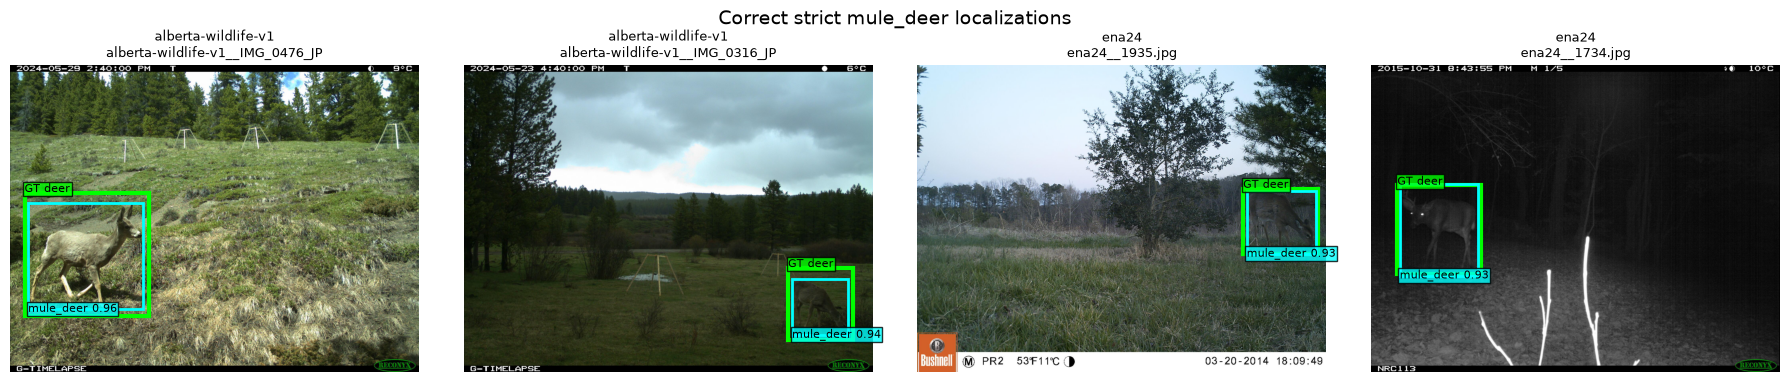

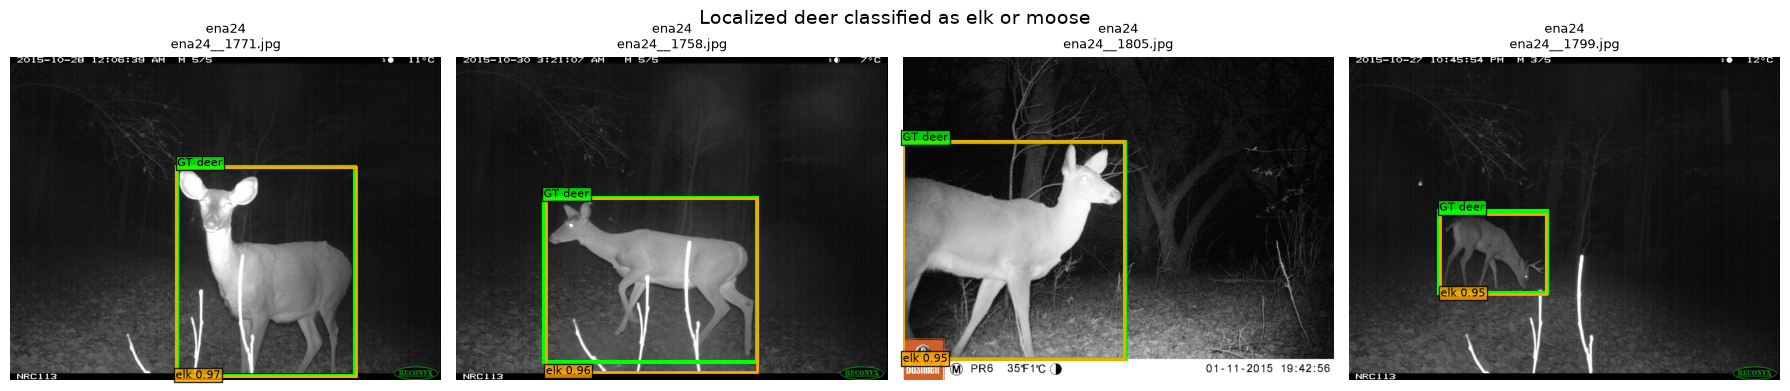

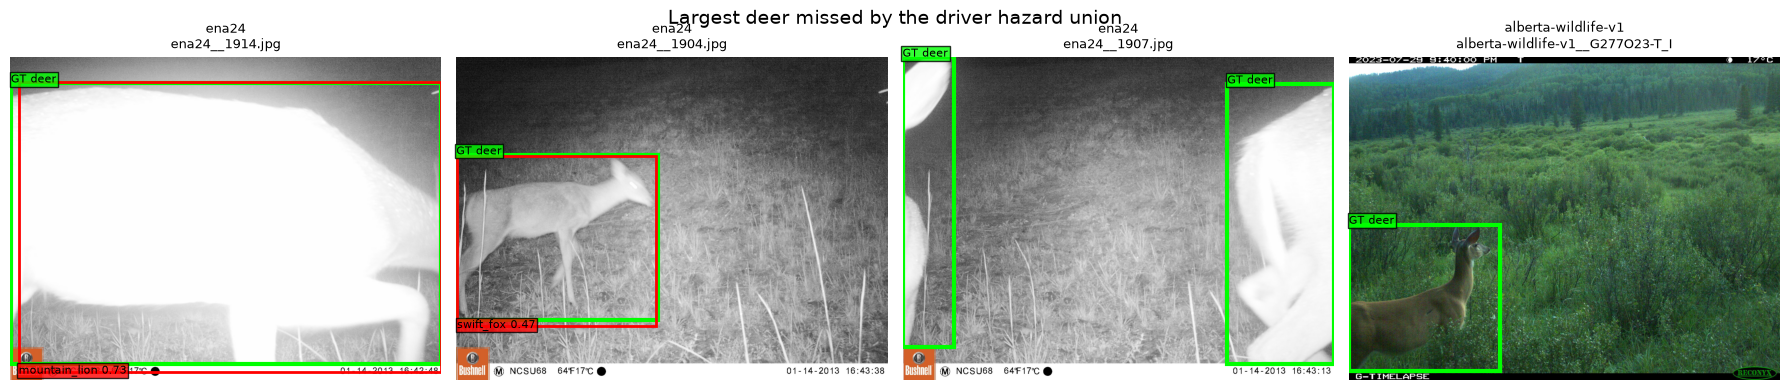

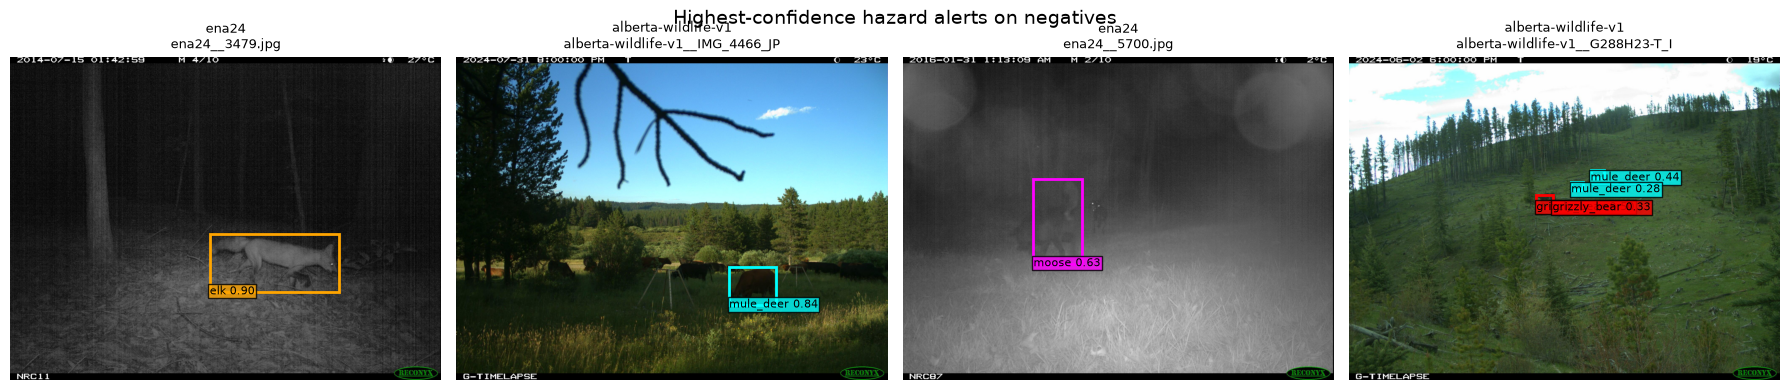

In [8]:
PREDICTION_COLORS = {
    'mule_deer': 'cyan',
    'elk': 'orange',
    'moose': 'magenta',
}


def draw_gallery(
    items: list[EvaluatedImage], title: str, limit: int = 4
) -> None:
    selected = items[:limit]
    if not selected:
        print(f'{title}: no examples')
        return
    figure, axes = plt.subplots(1, len(selected), figsize=(4.5 * len(selected), 4))
    if len(selected) == 1:
        axes = [axes]
    for axis, item in zip(axes, selected, strict=True):
        with Image.open(item.image) as source_image:
            image = source_image.convert('RGB')
        width, height = image.size
        axis.imshow(image)
        for box in item.ground_truth:
            x_min, y_min, x_max, y_max = box
            axis.add_patch(
                Rectangle(
                    (x_min * width, y_min * height),
                    (x_max - x_min) * width,
                    (y_max - y_min) * height,
                    fill=False,
                    color='lime',
                    linewidth=3,
                )
            )
            axis.text(
                x_min * width,
                max(0, y_min * height - 4),
                'GT deer',
                color='black',
                fontsize=8,
                bbox={'facecolor': 'lime', 'alpha': 0.8, 'pad': 1},
            )
        for prediction in item.predictions:
            if prediction.confidence < DISPLAY_CONFIDENCE:
                continue
            x_min, y_min, x_max, y_max = prediction.box
            color = PREDICTION_COLORS.get(prediction.label, 'red')
            axis.add_patch(
                Rectangle(
                    (x_min * width, y_min * height),
                    (x_max - x_min) * width,
                    (y_max - y_min) * height,
                    fill=False,
                    color=color,
                    linewidth=2,
                )
            )
            axis.text(
                x_min * width,
                min(height - 4, y_max * height + 12),
                f'{prediction.label} {prediction.confidence:.2f}',
                color='black',
                fontsize=8,
                bbox={'facecolor': color, 'alpha': 0.8, 'pad': 1},
            )
        axis.set_title(
            f'{item.source_dataset}\n{item.image.name[:32]}', fontsize=9
        )
        axis.axis('off')
    figure.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


draw_gallery(correct, 'Correct strict mule_deer localizations')
draw_gallery(confused, 'Localized deer classified as elk or moose')
draw_gallery(missed, 'Largest deer missed by the driver hazard union')
draw_gallery(false_alerts, 'Highest-confidence hazard alerts on negatives')


## Findings

On the 193-image test split (111 deer boxes), strict `mule_deer` evaluation produced AP50 **0.358**, mAP50–95 **0.155**, precision **0.660**, recall **0.297**, and F1 **0.410** at confidence 0.25. It is reasonably selective but misses roughly seven out of ten deer boxes.

The driver hazard union improved AP50 to **0.619**, mAP50–95 to **0.346**, precision to **0.673**, recall to **0.595**, and F1 to **0.632** at confidence 0.25. Its best observed test F1 was **0.695** at confidence **0.414**, with precision **0.855** and recall **0.586**.

Performance is strongly source-dependent. Hazard-union AP50 was **0.773** on ENA24 but **0.452** on Alberta. At confidence 0.25, hazard-union recall fell from **0.789** for large deer boxes to **0.531** for medium boxes and **0.417** for small boxes. The negative-image false-positive rate was **10.3%** for the hazard union, compared with **4.7%** for strict mule deer.

The baseline is useful, but not sufficient for a driver alert. A deer-focused fine-tune should prioritize small/distant deer and Alberta-style variation. The hazard union may be useful as an interim warning policy, but it must be calibrated on continuous road video before use because the current negatives are wildlife-dataset images rather than driving hours.


## Interpretation guardrails

- AP metrics use the derived bounding boxes and standard confidence-ranked, one-to-one IoU matching.
- Test results are primary; train and validation results diagnose split/source variation only.
- The safety union is useful for alert analysis but does not excuse taxonomic errors in wildlife-monitoring mode.
- This dataset remains camera-trap-heavy. It cannot establish false alerts per driving hour, first-visible alert latency, or night-road performance.
- Public model training provenance may overlap these public datasets; that possibility has not been ruled out.
- The YouTube dashcam clips should remain a separate qualitative video stress test until annotated and licensed.
